#Lab - 11
#Training and Understanding CNNs

Setting Up

In [ ]:
import math, time
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
from torchvision.utils import make_grid
import matplotlib.pyplot as plt
torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.11.0+cpu | device: cpu


In [ ]:
# Experiment 1: Weight Initialization
# 1.1 Fan-in and fan-out

def fans(w):
    """Fan-in and fan-out of a Conv2d or Linear weight tensor."""
    n_in = w[0].numel() # weights that feed ONE output value
    n_out = w.shape[0] * w[0, 0].numel() # kernel area x output channels
    return n_in, n_out

conv = nn.Conv2d(16, 32, 5) # 5x5 kernel, 16 -> 32 channels
print("fan_in, fan_out :", fans(conv.weight.data))
print("PyTorch agrees :", nn.init._calculate_fan_in_and_fan_out(conv.weight))
print("parameters :", sum(p.numel() for p in conv.parameters()))

fan_in, fan_out : (400, 800)
PyTorch agrees : (400, 800)
parameters : 12832


### 1.2 LeCun, Xavier and He from scratch

In [ ]:
def fill(w, var, uniform=False):
    """Fill tensor w with zero-mean random numbers of variance var."""
    if uniform:
        a = math.sqrt(3 * var) # U(-a, a) has variance a^2 / 3
        w.uniform_(-a, a)
    else:
        w.normal_(0, math.sqrt(var))

def lecun_init(w, uniform=False):
    n_in, _ = fans(w)
    fill(w, 1 / n_in, uniform)

def xavier_init(w, uniform=False):
    n_in, n_out = fans(w)
    fill(w, 2 / (n_in + n_out), uniform)

def he_init(w, uniform=False):
    n_in, _ = fans(w)
    fill(w, 2 / n_in, uniform)

w = nn.Conv2d(32, 64, 3).weight.data # n_in = 288, n_out = 576
n_in, n_out = fans(w)
print("n_in, n_out =", n_in, n_out)
schemes = [("LeCun", lecun_init, math.sqrt(1 / n_in)),
           ("Xavier", xavier_init, math.sqrt(2 / (n_in + n_out))),
           ("He", he_init, math.sqrt(2 / n_in))]
print(f"{'method':8s} {'target std':>11s} {'normal':>9s} {'uniform':>9s}")
for name, init, target in schemes:
    init(w); normal = w.std().item()
    init(w, uniform=True); uniform = w.std().item()
    print(f"{name:8s} {target:11.5f} {normal:9.5f} {uniform:9.5f}")

n_in, n_out = 288 576
method    target std    normal   uniform
LeCun        0.05893   0.05886   0.05868
Xavier       0.04811   0.04835   0.04820
He           0.08333   0.08343   0.08298


### 1.3 The same three with torch.nn.init

In [ ]:
inbuilt = {
    ("LeCun", False): lambda w: nn.init.kaiming_normal_(w, nonlinearity="linear"),
    ("LeCun", True): lambda w: nn.init.kaiming_uniform_(w, nonlinearity="linear"),
    ("Xavier", False): nn.init.xavier_normal_,
    ("Xavier", True): nn.init.xavier_uniform_,
    ("He", False): lambda w: nn.init.kaiming_normal_(w, nonlinearity="relu"),
    ("He", True): lambda w: nn.init.kaiming_uniform_(w, nonlinearity="relu"),
}
scratch = {"LeCun": lecun_init, "Xavier": xavier_init, "He": he_init}
w = nn.Conv2d(64, 128, 3).weight.data # n_in = 576, n_out = 1152
print(f"{'method':8s} {'shape':8s} {'scratch std':>12s} {'PyTorch std':>12s}")
for (name, uniform), torch_init in inbuilt.items():
    scratch[name](w, uniform); mine = w.std().item()
    torch_init(w); theirs = w.std().item()
    print(f"{name:8s} {'uniform' if uniform else 'normal':8s} {mine:12.5f} {theirs:12.5f}")

method   shape     scratch std  PyTorch std
LeCun    normal        0.04159      0.04169
LeCun    uniform       0.04169      0.04174
Xavier   normal        0.03393      0.03397
Xavier   uniform       0.03405      0.03395
He       normal        0.05900      0.05891
He       uniform       0.05887      0.05900


### 1.4 What the initializer does to a deep CNN

scheme               relu1     relu2     relu3     relu4     relu5     relu6
PyTorch default   3.98e-01  1.50e-01  9.85e-02  3.64e-02  1.98e-02  7.86e-03
LeCun             6.88e-01  4.59e-01  4.19e-01  2.61e-01  2.50e-01  1.60e-01
Xavier            2.85e-01  1.90e-01  1.42e-01  8.83e-02  6.89e-02  4.41e-02
He                9.73e-01  9.19e-01  1.19e+00  1.04e+00  1.41e+00  1.28e+00
std = 0.01        3.58e-02  4.05e-03  6.28e-04  9.38e-05  2.15e-05  4.67e-06


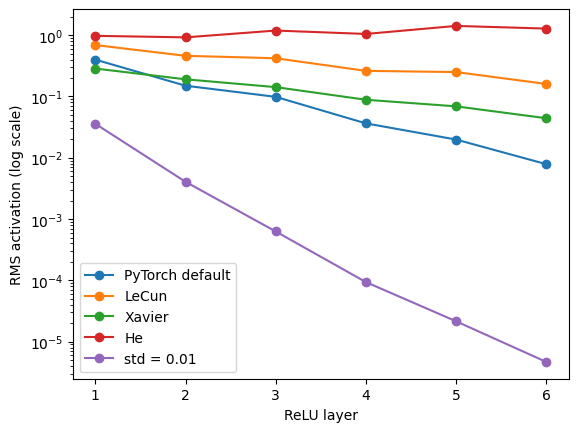

In [ ]:
def apply_init(model, init_fn):
    """Apply init_fn to the weights of every Conv2d / Linear layer; zero the biases."""
    def init_layer(m):
        if isinstance(m, (nn.Conv2d, nn.Linear)):
            init_fn(m.weight.data)
            m.bias.data.zero_()
    model.apply(init_layer) # runs init_layer on every sub-module
    return model

class CNN(nn.Module):
    """Six 3x3 conv layers, no BatchNorm - so the initializer alone sets the scale."""
    def __init__(self):
        super().__init__()
        ch, layers = [3, 32, 32, 64, 64, 128, 128], []
        for i in range(6):
            layers += [nn.Conv2d(ch[i], ch[i + 1], 3, padding=1), nn.ReLU()]
            if i % 2 == 1:
                layers.append(nn.MaxPool2d(2))
        self.features = nn.Sequential(*layers) # 32x32 -> 4x4
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(128 * 4 * 4, 10))
    def forward(self, x):
        return self.classifier(self.features(x))

inits = {"PyTorch default": lambda w: nn.init.kaiming_uniform_(w, a=math.sqrt(5)),
         "LeCun": lecun_init,
         "Xavier": xavier_init,
         "He": he_init,
         "std = 0.01": lambda w: w.normal_(0, 0.01)}

def activation_scales(init_fn):
    """RMS activation after each ReLU for one batch of random input."""
    torch.manual_seed(0)
    model = apply_init(CNN(), init_fn).eval()
    h, scales = torch.randn(64, 3, 32, 32), []
    with torch.no_grad():
        for layer in model.features:
            h = layer(h)
            if isinstance(layer, nn.ReLU):
                scales.append(h.pow(2).mean().sqrt().item())
    return scales

print(f"{'scheme':16s}" + "".join(f"{'relu' + str(i + 1):>10s}" for i in range(6)))
for name, fn in inits.items():
    s = activation_scales(fn)
    print(f"{name:16s}" + "".join(f"{v:10.2e}" for v in s))
    plt.semilogy(range(1, 7), s, marker="o", label=name)

plt.xlabel("ReLU layer")
plt.ylabel("RMS activation (log scale)")
plt.legend()
plt.show()

### 1.5 Does it matter for training?

In [ ]:
from torch.utils.data import Subset, DataLoader

transform = transforms.Compose([transforms.ToTensor(),
                                transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])
train_set = torchvision.datasets.CIFAR10("./data", train=True, download=True, transform=transform)
test_set = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=transform)
classes = train_set.classes

def train(model, epochs, n_images):
    """Train with SGD on the first n_images training images; return test accuracy (%)."""
    loader = DataLoader(Subset(train_set, range(n_images)), batch_size=128, shuffle=True)
    optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
    model.to(device).train()
    for _ in range(epochs):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            F.cross_entropy(model(x), y).backward()
            optimizer.step()
    model.eval()
    correct = 0
    with torch.no_grad():
        for x, y in DataLoader(Subset(test_set, range(2000)), batch_size=500):
            correct += (model(x.to(device)).argmax(1).cpu() == y).sum().item()
    return 100 * correct / 2000

for name, fn in inits.items():
    torch.manual_seed(0)
    acc = train(apply_init(CNN(), fn), epochs=2, n_images=5000)
    print(f"{name:16s} test accuracy after 2 epochs: {acc:5.2f}%")

100%|██████████| 170M/170M [39:53<00:00, 71.2kB/s]


PyTorch default  test accuracy after 2 epochs:  9.90%
LeCun            test accuracy after 2 epochs: 28.30%
Xavier           test accuracy after 2 epochs: 25.50%
He               test accuracy after 2 epochs: 37.05%
std = 0.01       test accuracy after 2 epochs:  9.90%


## Experiment 2: Visualizing a Trained CNN

### 2.0 Train the network and pick an image

In [ ]:
!pip install -q captum

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 7.9 MB/s eta 0:00:00


In [ ]:
from captum.attr import (Saliency, IntegratedGradients, GuidedBackprop,
                        LayerGradCam, GuidedGradCam, Occlusion, LayerAttribution)
torch.manual_seed(0)
model = apply_init(CNN(), he_init).to(device)
filters_before = model.features[0].weight.data.cpu().clone() # keep for Section 2.1
print(f"test accuracy after training: {train(model, epochs=3, n_images=10000):.1f}%")
for image, label in test_set: # first test image the network classifies correctly
    if model(image[None].to(device)).argmax(1).item() == label:
        break
x = image[None].to(device).requires_grad_() # add a batch dimension: 1 x 3 x 32 x 32
print("chosen image:", classes[label], "| input shape:", tuple(x.shape))
def show(t): # undo the normalisation so the image displays correctly
    return (t.cpu() / 2 + 0.5).clamp(0, 1).permute(1, 2, 0)

test accuracy after training: 51.6%
chosen image: cat | input shape: (1, 3, 32, 32)


### 2.1 First-layer filters

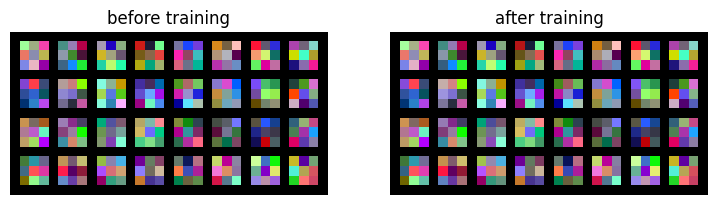

In [ ]:
filters_after = model.features[0].weight.data.cpu() # 32 filters, each 3 x 3 x 3
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, w, title in zip(axes, [filters_before, filters_after], ["before training", "after training"]):
    grid = make_grid(w, nrow=8, normalize=True, scale_each=True, padding=1)
    ax.imshow(grid.permute(1, 2, 0)); ax.set_title(title); ax.axis("off")
plt.show()

### 2.2 Feature maps

early layer: activation shape (32, 32, 32)
late layer: activation shape (128, 8, 8)


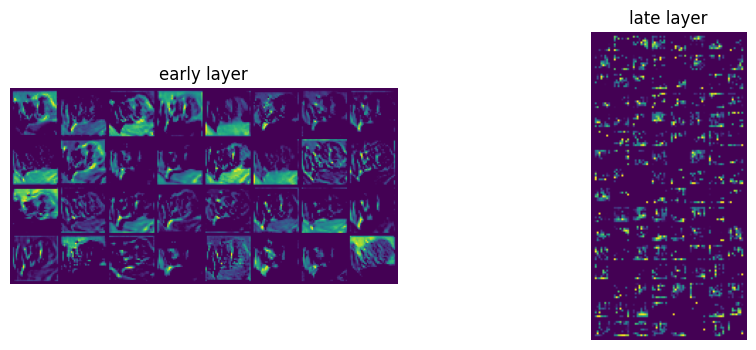

In [ ]:
maps = {}
def save_to(name):
    def hook(module, inputs, output):
        maps[name] = output.detach() # called automatically during the forward pass
    return hook
h1 = model.features[1].register_forward_hook(save_to("early layer")) # ReLU after conv 1
h2 = model.features[13].register_forward_hook(save_to("late layer")) # ReLU after conv 6
model(x)
h1.remove(); h2.remove() # always remove hooks when finished
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, A) in zip(axes, maps.items()):
    print(f"{name}: activation shape {tuple(A[0].shape)}")
    grid = make_grid(A[0].unsqueeze(1).cpu(), nrow=8, normalize=True, scale_each=True)
    ax.imshow(grid[0], cmap="viridis"); ax.set_title(name); ax.axis("off")
plt.show()

### 2.3 Gradient-based maps with Captum

/usr/local/lib/python3.13/dist-packages/captum/attr/_core/guided_backprop_deconvnet.py:66: UserWarning: Setting backward hooks on ReLU activations.The hooks will be removed after the attribution is finished
  warnings.warn(


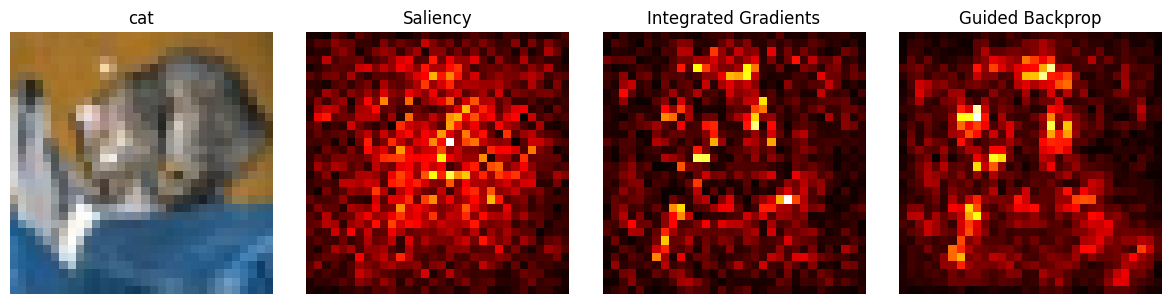

In [ ]:
def to_map(attr): # 1 x 3 x H x W attribution -> H x W map
    return attr.abs().amax(dim=1)[0].detach().cpu()
methods = {"Saliency": Saliency(model),
           "Integrated Gradients": IntegratedGradients(model),
           "Guided Backprop": GuidedBackprop(model)}
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
axes[0].imshow(show(image)); axes[0].set_title(classes[label])
for ax, (name, method) in zip(axes[1:], methods.items()):
    attr = method.attribute(x, target=label) # one line per method
    ax.imshow(to_map(attr), cmap="hot"); ax.set_title(name)
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

### 2.4 Grad-CAM and Guided Grad-CAM

Grad-CAM: (1, 1, 8, 8) -> upsampled (1, 1, 32, 32)


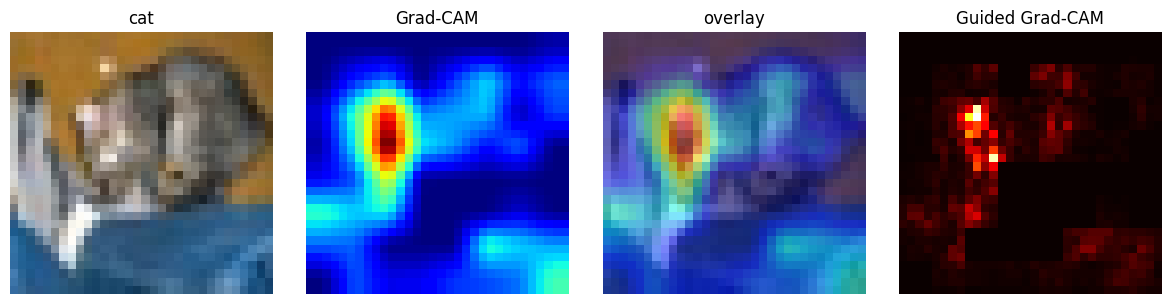

In [ ]:
layer = model.features[13] # last ReLU = output of the last conv block
cam = LayerGradCam(model, layer).attribute(x, target=label, relu_attributions=True)
cam_up = LayerAttribution.interpolate(cam, (32, 32), interpolate_mode="bilinear")
guided_cam = GuidedGradCam(model, layer).attribute(x, target=label)
print("Grad-CAM:", tuple(cam.shape), "-> upsampled", tuple(cam_up.shape))
heat = cam_up[0, 0].detach().cpu()
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
axes[0].imshow(show(image)); axes[0].set_title(classes[label])
axes[1].imshow(heat, cmap="jet"); axes[1].set_title("Grad-CAM")
axes[2].imshow(show(image)); axes[2].imshow(heat, cmap="jet", alpha=0.5);
axes[2].set_title("overlay")
axes[3].imshow(to_map(guided_cam), cmap="hot"); axes[3].set_title("Guided Grad-CAM")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

### 2.5 Occlusion and the cost of each method

Occlusion map: (32, 32) | forward passes: 196


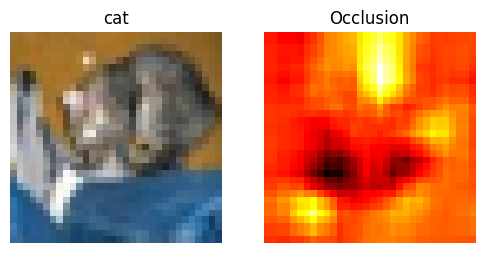

In [ ]:
attr = Occlusion(model).attribute(x, target=label,
                                 sliding_window_shapes=(3, 5, 5), # 5x5 patch, all 3 colours
                                 strides=(3, 2, 2), # slide 2 pixels at a time
                                 baselines=0) # hide the patch with grey
occ_map = attr[0].sum(dim=0).detach().cpu() # bright = hiding this lowers the class score
print("Occlusion map:", tuple(occ_map.shape), "| forward passes:", 14 * 14)
fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(show(image)); axes[0].set_title(classes[label])
axes[1].imshow(occ_map, cmap="hot"); axes[1].set_title("Occlusion")
for ax in axes: ax.axis("off")
plt.show()

In [ ]:
def timed(name, run):
    start = time.time(); run()
    print(f"{name:22s} {1000 * (time.time() - start):8.1f} ms")
timed("Saliency", lambda: Saliency(model).attribute(x, target=label))
timed("Guided Backprop", lambda: GuidedBackprop(model).attribute(x, target=label))
timed("Grad-CAM", lambda: LayerGradCam(model, layer).attribute(x, target=label))
timed("Integrated Gradients", lambda: IntegratedGradients(model).attribute(x, target=label))
timed("Occlusion", lambda: Occlusion(model).attribute(x, target=label,
                                                     sliding_window_shapes=(3, 5, 5), strides=(3, 2, 2)))

Saliency                   10.3 ms
Guided Backprop             8.3 ms
Grad-CAM                    4.2 ms
Integrated Gradients      212.7 ms
Occlusion                 890.9 ms


```markdown
## Lab Exercises

### Exercise 1: Target Class Sensitivity in Grad-CAM
Try running Grad-CAM with a different target class (e.g., another class index from `classes`). Does the Grad-CAM region shift to target features associated with that incorrect class?

### Exercise 2: Guided Backpropagation Weight Randomization
Verify if Guided Backpropagation is truly sensitive to network weights by testing it with a randomly initialized model compared to your trained model. Does the attribution visualization change significantly?

### Exercise 3: Hyperparameter Search on Occlusion Maps
Experiment with different sliding window shapes (e.g., `(3, 3, 3)` or `(3, 8, 8)`) and stride parameters. How do the resolution of the Occlusion map and the computational time scale with these changes?
```

### Exercise 1: Target Class Sensitivity in Grad-CAM

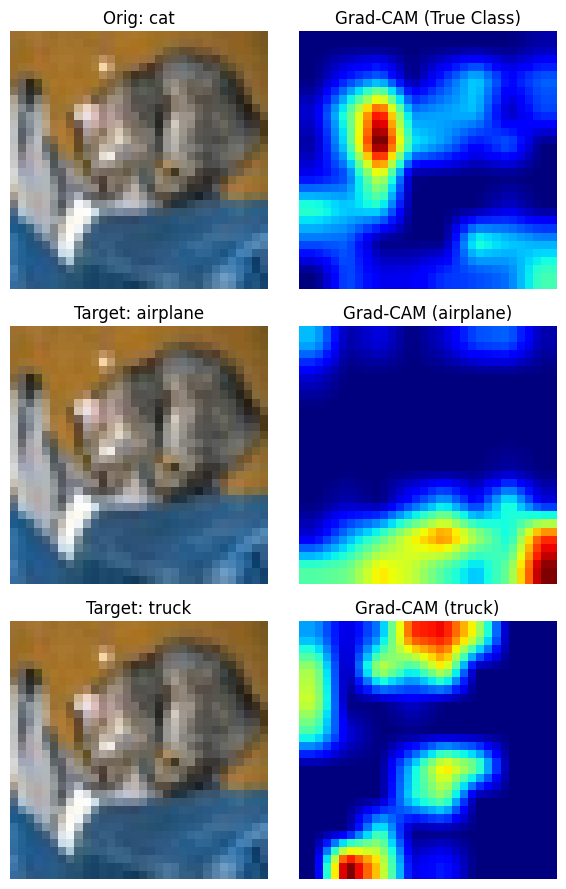

In [ ]:
import numpy as np

# Let's try visualizing different incorrect classes (e.g. 'truck' [9] or 'airplane' [0])
incorrect_labels = [0, 9]
fig, axes = plt.subplots(len(incorrect_labels) + 1, 2, figsize=(6, 3 * (len(incorrect_labels) + 1)))

# Standard correctly classified target (cat)
layer = model.features[13]
cam_correct = LayerGradCam(model, layer).attribute(x, target=label, relu_attributions=True)
cam_up_correct = LayerAttribution.interpolate(cam_correct, (32, 32), interpolate_mode="bilinear")[0, 0].detach().cpu()
axes[0, 0].imshow(show(image))
axes[0, 0].set_title(f"Orig: {classes[label]}")
axes[0, 0].axis("off")
axes[0, 1].imshow(cam_up_correct, cmap="jet")
axes[0, 1].set_title("Grad-CAM (True Class)")
axes[0, 1].axis("off")

for i, target_class in enumerate(incorrect_labels, start=1):
    cam_wrong = LayerGradCam(model, layer).attribute(x, target=target_class, relu_attributions=True)
    cam_up_wrong = LayerAttribution.interpolate(cam_wrong, (32, 32), interpolate_mode="bilinear")[0, 0].detach().cpu()

    axes[i, 0].imshow(show(image))
    axes[i, 0].set_title(f"Target: {classes[target_class]}")
    axes[i, 0].axis("off")
    axes[i, 1].imshow(cam_up_wrong, cmap="jet")
    axes[i, 1].set_title(f"Grad-CAM ({classes[target_class]})")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

### Exercise 2: Guided Backpropagation Weight Randomization

/usr/local/lib/python3.13/dist-packages/captum/attr/_core/guided_backprop_deconvnet.py:66: UserWarning: Setting backward hooks on ReLU activations.The hooks will be removed after the attribution is finished
  warnings.warn(


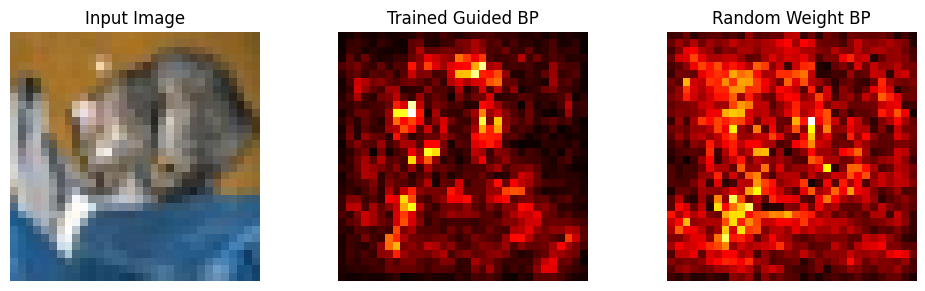

In [ ]:
# Initialize a random model of same structure to test against
random_model = CNN().to(device).eval()
gb_trained = GuidedBackprop(model)
gb_random = GuidedBackprop(random_model)

attr_trained = gb_trained.attribute(x, target=label)
attr_random = gb_random.attribute(x, target=label)

fig, axes = plt.subplots(1, 3, figsize=(10, 3))
axes[0].imshow(show(image))
axes[0].set_title("Input Image")
axes[0].axis("off")

axes[1].imshow(to_map(attr_trained), cmap="hot")
axes[1].set_title("Trained Guided BP")
axes[1].axis("off")

axes[2].imshow(to_map(attr_random), cmap="hot")
axes[2].set_title("Random Weight BP")
axes[2].axis("off")

plt.tight_layout()
plt.show()

### Exercise 3: Hyperparameter Search on Occlusion Maps

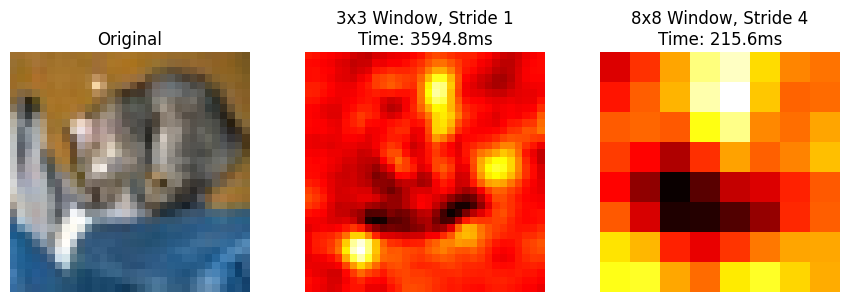

In [ ]:
# Compare smaller (3x3) vs larger (8x8) occlusion patches with timings
configs = [
    {"window": (3, 3, 3), "stride": (3, 1, 1), "desc": "3x3 Window, Stride 1"},
    {"window": (3, 8, 8), "stride": (3, 4, 4), "desc": "8x8 Window, Stride 4"}
]

fig, axes = plt.subplots(1, len(configs) + 1, figsize=(3 * (len(configs) + 1), 3))
axes[0].imshow(show(image))
axes[0].set_title("Original")
axes[0].axis("off")

for idx, cfg in enumerate(configs, start=1):
    t0 = time.time()
    occ_attr = Occlusion(model).attribute(x, target=label,
                                           sliding_window_shapes=cfg["window"],
                                           strides=cfg["stride"],
                                           baselines=0)
    elapsed = (time.time() - t0) * 1000
    occ_map_res = occ_attr[0].sum(dim=0).detach().cpu()

    axes[idx].imshow(occ_map_res, cmap="hot")
    axes[idx].set_title(f"{cfg['desc']}\nTime: {elapsed:.1f}ms")
    axes[idx].axis("off")

plt.tight_layout()
plt.show()